In [636]:
import pandas as pd
import numpy as np 
import talib #conda install -c conda-forge ta-lib ---how to download
import yfinance as yf
import hvplot.pandas
import matplotlib.pyplot as plt



In [637]:
ticker = "AAPL"

In [638]:
ticker_data = yf.download(ticker, '2018-01-01', '2022-08-04')

[*********************100%***********************]  1 of 1 completed


In [639]:
print(ticker_data)

                  Open        High         Low       Close   Adj Close  \
Date                                                                     
2018-01-02   42.540001   43.075001   42.314999   43.064999   41.075401   
2018-01-03   43.132500   43.637501   42.990002   43.057499   41.068260   
2018-01-04   43.134998   43.367500   43.020000   43.257500   41.259010   
2018-01-05   43.360001   43.842499   43.262501   43.750000   41.728764   
2018-01-08   43.587502   43.902500   43.482498   43.587502   41.573765   
...                ...         ...         ...         ...         ...   
2022-07-28  156.979996  157.639999  154.410004  157.350006  157.350006   
2022-07-29  161.240005  163.630005  159.500000  162.509995  162.509995   
2022-08-01  161.009995  163.589996  160.889999  161.509995  161.509995   
2022-08-02  160.100006  162.410004  159.630005  160.009995  160.009995   
2022-08-03  160.839996  166.589996  160.750000  166.130005  166.130005   

               Volume  
Date         

In [640]:
ticker_chart = ticker_data['Close'].hvplot()
ticker_chart

:Curve   [Date]   (Close)

In [641]:
timeperiod = 14
rsi = talib.RSI(ticker_data["Close"],timeperiod)
print(rsi)

Date
2018-01-02          NaN
2018-01-03          NaN
2018-01-04          NaN
2018-01-05          NaN
2018-01-08          NaN
                ...    
2022-07-28    64.975795
2022-07-29    70.162535
2022-08-01    68.059010
2022-08-02    64.915141
2022-08-03    70.834717
Length: 1155, dtype: float64


In [642]:
rsi_df = pd.DataFrame(rsi)
rsi_df.columns = ['RSI']
print(rsi_df)

                  RSI
Date                 
2018-01-02        NaN
2018-01-03        NaN
2018-01-04        NaN
2018-01-05        NaN
2018-01-08        NaN
...               ...
2022-07-28  64.975795
2022-07-29  70.162535
2022-08-01  68.059010
2022-08-02  64.915141
2022-08-03  70.834717

[1155 rows x 1 columns]


In [643]:
data_rsi = pd.concat([ticker_data,rsi_df],axis=1)
data_rsi

,Open,High,Low,Close,Adj Close,Volume,RSI
Date,,,,,,,
2018-01-02,42.540001,43.075001,42.314999,43.064999,41.075401,102223600,NaN
2018-01-03,43.132500,43.637501,42.990002,43.057499,41.068260,118071600,NaN
2018-01-04,43.134998,43.367500,43.020000,43.257500,41.259010,89738400,NaN
2018-01-05,43.360001,43.842499,43.262501,43.750000,41.728764,94640000,NaN
2018-01-08,43.587502,43.902500,43.482498,43.587502,41.573765,82271200,NaN
...,...,...,...,...,...,...,...
2022-07-28,156.979996,157.639999,154.410004,157.350006,157.350006,81378700,64.975795
2022-07-29,161.240005,163.630005,159.500000,162.509995,162.509995,101689200,70.162535
2022-08-01,161.009995,163.589996,160.889999,161.509995,161.509995,67829400,68.059010


In [644]:
data_rsi['returns'] = data_rsi['Close'].pct_change()
data_rsi['up'] = np.maximum(data_rsi['Close'].diff(),0)
data_rsi['down'] = np.maximum(data_rsi['Close'].diff(),0)
data_rsi

,Open,High,Low,Close,Adj Close,Volume,RSI,returns,up,down
Date,,,,,,,,,,
2018-01-02,42.540001,43.075001,42.314999,43.064999,41.075401,102223600,NaN,NaN,NaN,NaN
2018-01-03,43.132500,43.637501,42.990002,43.057499,41.068260,118071600,NaN,-0.000174,0.000000,0.000000
2018-01-04,43.134998,43.367500,43.020000,43.257500,41.259010,89738400,NaN,0.004645,0.200001,0.200001
2018-01-05,43.360001,43.842499,43.262501,43.750000,41.728764,94640000,NaN,0.011385,0.492500,0.492500
2018-01-08,43.587502,43.902500,43.482498,43.587502,41.573765,82271200,NaN,-0.003714,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
2022-07-28,156.979996,157.639999,154.410004,157.350006,157.350006,81378700,64.975795,0.003572,0.560013,0.560013
2022-07-29,161.240005,163.630005,159.500000,162.509995,162.509995,101689200,70.162535,0.032793,5.159988,5.159988
2022-08-01,161.009995,163.589996,160.889999,161.509995,161.509995,67829400,68.059010,-0.006153,0.000000,0.000000


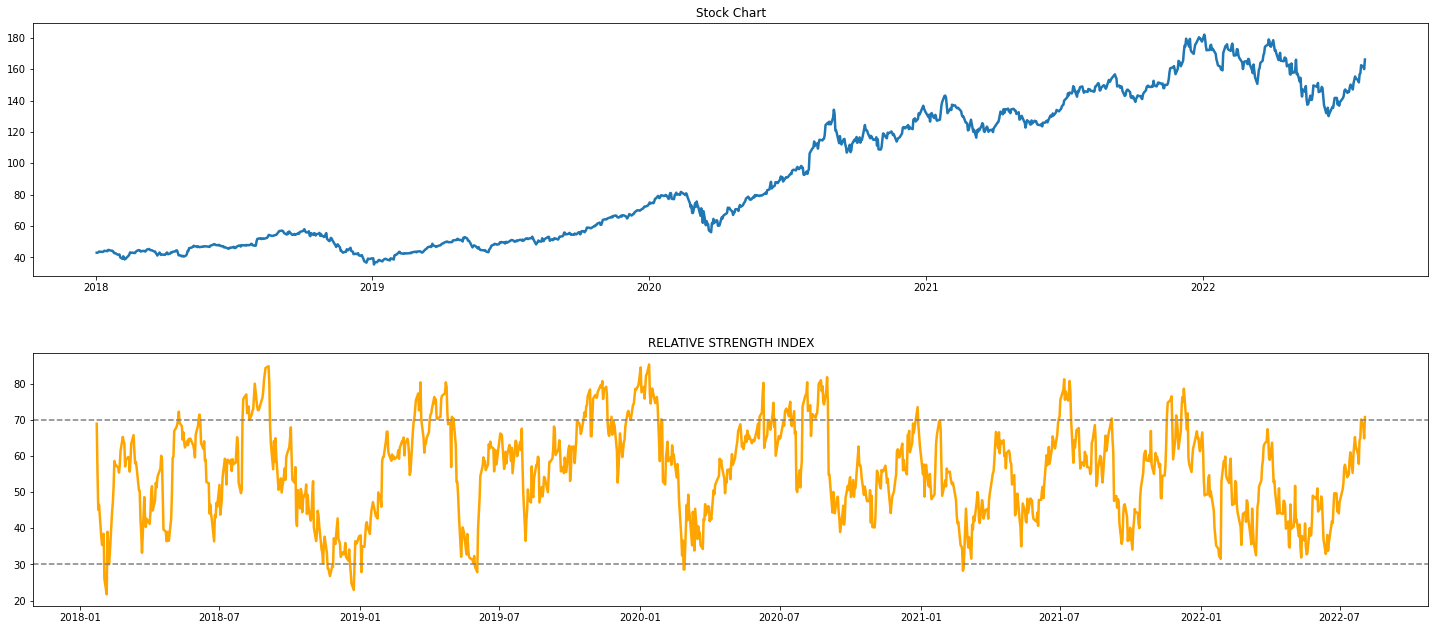

In [645]:
fig = plt.figure()
fig.set_size_inches((25, 18))
ax1 = plt.subplot2grid((15,1), (0,0), rowspan = 4, colspan = 1)
ax2 = plt.subplot2grid((15,1), (5,0), rowspan = 4, colspan = 1)
ax1.plot(data_rsi['Close'], linewidth = 2.5)
ax1.set_title('Stock Chart')
ax2.plot(data_rsi['RSI'], color = 'orange', linewidth = 2.5)
ax2.axhline(30, linestyle = '--', linewidth = 1.5, color = 'grey')
ax2.axhline(70, linestyle = '--', linewidth = 1.5, color = 'grey')
ax2.set_title('RELATIVE STRENGTH INDEX')
plt.show()

In [646]:
rsi_chart = rsi.hvplot()
rsi_chart

:Curve   [Date]   (0)

In [647]:

data_rsi['signal'] = 1*(data_rsi.loc[:,["RSI"]]<30) - 1*(data_rsi.loc[:,["RSI"]]>70)
data_rsi['Entry/Exit'] = data_rsi['signal'].diff()

In [648]:
print(data_rsi)

                  Open        High         Low       Close   Adj Close  \
Date                                                                     
2018-01-02   42.540001   43.075001   42.314999   43.064999   41.075401   
2018-01-03   43.132500   43.637501   42.990002   43.057499   41.068260   
2018-01-04   43.134998   43.367500   43.020000   43.257500   41.259010   
2018-01-05   43.360001   43.842499   43.262501   43.750000   41.728764   
2018-01-08   43.587502   43.902500   43.482498   43.587502   41.573765   
...                ...         ...         ...         ...         ...   
2022-07-28  156.979996  157.639999  154.410004  157.350006  157.350006   
2022-07-29  161.240005  163.630005  159.500000  162.509995  162.509995   
2022-08-01  161.009995  163.589996  160.889999  161.509995  161.509995   
2022-08-02  160.100006  162.410004  159.630005  160.009995  160.009995   
2022-08-03  160.839996  166.589996  160.750000  166.130005  166.130005   

               Volume        RSI   re

In [649]:
overbought= (data_rsi.loc[:,["RSI"]]>70)

oversold= (data_rsi.loc[:,["RSI"]]<30) 
entry = data_rsi[oversold].hvplot.scatter(
    color='green',
    marker='^',
    width=1000,
    height=400)
exit = data_rsi[overbought].hvplot.scatter(
    color='red',
    marker='v',
    width=1000,
    height=400)

In [650]:
entry*exit

:Overlay
   .NdOverlay.I  :NdOverlay   [Variable]
      :Scatter   [Date]   (value)
   .NdOverlay.II :NdOverlay   [Variable]
      :Scatter   [Date]   (value)

In [651]:
rsi_entry_exit_plot = entry * exit * rsi_chart
rsi_entry_exit_plot

:Overlay
   .NdOverlay.I  :NdOverlay   [Variable]
      :Scatter   [Date]   (value)
   .NdOverlay.II :NdOverlay   [Variable]
      :Scatter   [Date]   (value)
   .Curve.A_0    :Curve   [Date]   (0)

In [652]:
initial_capital = float(100000)
share_size = 500

In [653]:
data_rsi['Position'] = share_size * data_rsi['signal']
data_rsi['Entry/Exit Position'] = data_rsi["Position"].diff()
data_rsi["Portfolio Holdings"] = data_rsi["Close"] * data_rsi["Entry/Exit Position"].cumsum()
data_rsi['Portfolio Cash']= ( initial_capital - (data_rsi["Close"] * data_rsi["Entry/Exit Position"]).cumsum())
data_rsi["Portfolio Total"] = data_rsi["Portfolio Cash"] + data_rsi["Portfolio Holdings"]
data_rsi["Portfolio Daily Returns"] = data_rsi["Portfolio Total"].pct_change()
data_rsi["Portfolio Cumulative Returns"] = (1 + data_rsi["Portfolio Daily Returns"]).cumprod() - 1
data_rsi

,Open,High,Low,Close,Adj Close,Volume,RSI,returns,up,down,signal,Entry/Exit,Position,Entry/Exit Position,Portfolio Holdings,Portfolio Cash,Portfolio Total,Portfolio Daily Returns,Portfolio Cumulative Returns
Date,,,,,,,,,,,,,,,,,,,
2018-01-02,42.540001,43.075001,42.314999,43.064999,41.075401,102223600,NaN,NaN,NaN,NaN,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-03,43.132500,43.637501,42.990002,43.057499,41.068260,118071600,NaN,-0.000174,0.000000,0.000000,0,0.0,0,0.0,0.000000,100000.000000,100000.000000,NaN,NaN
2018-01-04,43.134998,43.367500,43.020000,43.257500,41.259010,89738400,NaN,0.004645,0.200001,0.200001,0,0.0,0,0.0,0.000000,100000.000000,100000.000000,0.000000,0.000000
2018-01-05,43.360001,43.842499,43.262501,43.750000,41.728764,94640000,NaN,0.011385,0.492500,0.492500,0,0.0,0,0.0,0.000000,100000.000000,100000.000000,0.000000,0.000000
2018-01-08,43.587502,43.902500,43.482498,43.587502,41.573765,82271200,NaN,-0.003714,0.000000,0.000000,0,0.0,0,0.0,0.000000,100000.000000,100000.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-07-28,156.979996,157.639999,154.410004,157.350006,157.350006,81378700,64.975795,0.003572,0.560013,0.560013,0,0.0,0,0.0,0.000000,97147.504807,97147.504807,0.000000,-0.028525
2022-07-29,161.240005,163.630005,159.500000,162.509995,162.509995,101689200,70.162535,0.032793,5.159988,5.159988,-1,-1.0,-500,-500.0,-81254.997253,178402.502060,97147.504807,0.000000,-0.028525
2022-08-01,161.009995,163.589996,160.889999,161.509995,161.509995,67829400,68.059010,-0.006153,0.000000,0.000000,0,1.0,0,500.0,0.000000,97647.504807,97647.504807,0.005147,-0.023525


In [654]:
trade_evaluation_df = pd.DataFrame(
    columns=[
        'Stock', 
        'Entry Date', 
        'Exit Date', 
        'Shares', 
        'Entry Share Price', 
        'Exit Share Price', 
        'Entry Portfolio Holding', 
        'Exit Portfolio Holding', 
        'Profit/Loss']
)

In [655]:
# Initialize the iterative variables
entry_date = ""
exit_date = ""
entry_portfolio_holding = 0.0
exit_portfolio_holding = 0.0
share_size = 0
entry_share_price = 0.0
exit_share_price = 0.0


# Loop through the signal DataFrame
# If `Entry/Exit` is 1, set entry trade metrics
# Else if `Entry/Exit` is -1, set exit trade metrics and calculate profit,
# Then append the record to the trade evaluation DataFrame
for index, row in data_rsi.iterrows():
    if row['Entry/Exit'] == 1:
        entry_date = index
        entry_portfolio_holding = entry_share_price * share_size
        share_size = 500
        entry_share_price = row['Close']
        
    elif row['Entry/Exit'] == -1:
        exit_date = index
        exit_portfolio_holding = abs(row['Close'] * row['Entry/Exit Position'])
        exit_share_price = row['Close']
        profit_loss =  exit_portfolio_holding - entry_portfolio_holding
        trade_evaluation_df = trade_evaluation_df.append(
            {
                'Stock': 'AAPL',
                'Entry Date': entry_date,
                'Exit Date': exit_date,
                'Shares': share_size,
                'Entry Share Price': entry_share_price,
                'Exit Share Price': exit_share_price,
                'Entry Portfolio Holding': entry_portfolio_holding,
                'Exit Portfolio Holding': exit_portfolio_holding,
                'Profit/Loss': profit_loss
            },
            ignore_index=True)

        

# Review the DataFrame
trade_evaluation_df 

,Stock,Entry Date,Exit Date,Shares,Entry Share Price,Exit Share Price,Entry Portfolio Holding,Exit Portfolio Holding,Profit/Loss
0,AAPL,2018-02-02,2018-02-06,500,40.125000,40.757500,0.000000,20378.749847,20378.749847
1,AAPL,2018-02-02,2018-05-09,500,40.125000,46.840000,0.000000,23420.000076,23420.000076
2,AAPL,2018-05-11,2018-06-05,500,47.147499,48.327499,20062.500000,24163.749695,4101.249695
3,AAPL,2018-06-07,2018-08-01,500,48.365002,50.375000,23573.749542,25187.500000,1613.750458
4,AAPL,2018-08-10,2018-08-13,500,51.882500,52.217499,24182.500839,26108.749390,1926.248550
5,AAPL,2018-11-20,2018-11-28,500,44.244999,45.235001,27887.500763,22617.500305,-5270.000458
6,AAPL,2018-12-20,2018-12-26,500,39.207500,39.292500,22122.499466,19646.249771,-2476.249695
7,AAPL,2019-01-03,2019-01-04,500,35.547501,37.064999,19603.750229,18532.499313,-1071.250916
8,AAPL,2019-01-03,2019-03-13,500,35.547501,45.427502,19603.750229,22713.750839,3110.000610
9,AAPL,2019-03-25,2019-04-03,500,47.185001,48.837502,17773.750305,24418.750763,6645.000458


In [657]:
total_profit_loss = round(trade_evaluation_df['Profit/Loss'].sum(),2)
total_profit_loss

159028.76

In [661]:
roi = round((total_profit_loss / (initial_capital))*100,2)
print(f"{roi}%")

159.03%
